# Step 2 — Pretraining a ~100M Transformer (v2) on Kaggle 2× T4

**What this notebook does, in plain words:** it trains a 100M-parameter language model on the ~1.6B-token mix from Step 1 (web text, explanations, Wikipedia, stories), using **both** Kaggle T4 GPUs. The result is a *base model*: it continues text well but doesn't answer questions yet. That's Step 3 (fine-tuning).

| | v1 (TinyStories) | **v2** |
|---|---|---|
| Parameters | 13.8M | **100.7M** |
| Layers × width × heads | 6 × 384 × 6 | 12 × 768 × 12 query / **4 key-value** heads |
| Vocab / context | 8k / 512 | 32k / 1,024 |
| Norm / MLP | LayerNorm / GELU | **RMSNorm / SwiGLU** |
| Attention extras | — | **GQA + QK-norm** |
| GPUs | 1 | **2 (DDP)** |
| LR schedule | warm-up + cosine | **warm-up → stable → decay (WSD)** |

### How to run
1. *Add Input* → the dataset from Step 1 (or Step 1's notebook output).
2. *Settings → Accelerator → **GPU T4 x2***, *Internet → On*.
3. Run the cells **up to and including the speed test** first (≈10 min). It prints the real speed and how many sessions the full run needs.
4. *Save Version → **Save & Run All*** for the real run. The time guard stops cleanly after 11 h and saves a checkpoint.
5. **Next session:** *Add Input* → this notebook's previous version output, then Save & Run All again. Training resumes from the last checkpoint automatically. Repeat until it prints `[done]`.

## 0. Setup and pre-flight checks

In [1]:
import os, sys, glob, json, shutil, math, time, importlib
import numpy as np
import torch
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

# ---- find the data from Step 1 (manifest.json)
def find_data():
    cands = [os.environ.get("LLM_DATA", "")]
    cands += [os.path.dirname(p) for p in glob.glob("/kaggle/input/**/manifest.json", recursive=True)]
    cands += ["./llm_data", "/content/llm_data"]
    for d in cands:
        if d and os.path.exists(os.path.join(d, "manifest.json")):
            return os.path.abspath(d)
    return None

DATA_DIR = find_data()
OUT_DIR = "/kaggle/working/tv2_run" if os.path.isdir("/kaggle/working") else os.path.abspath("./tv2_run")
os.makedirs(OUT_DIR, exist_ok=True)

problems = []
if DATA_DIR is None:
    problems.append("manifest.json not found — attach the Step 1 dataset (Add Input) or set LLM_DATA")
else:
    manifest = json.load(open(os.path.join(DATA_DIR, "manifest.json")))
    if manifest.get("smoke") and not SMOKE_TEST:
        problems.append("the attached data is the SMOKE_TEST data — attach the real Step 1 output")
n_gpu = torch.cuda.device_count()
if n_gpu == 0 and not SMOKE_TEST:
    problems.append("no GPU — Settings → Accelerator → GPU T4 x2")
free_gb = shutil.disk_usage(OUT_DIR).free / 1e9
if free_gb < (0.1 if SMOKE_TEST else 6):
    problems.append(f"only {free_gb:.1f} GB free disk; checkpoints need ~3 GB")
if problems:
    raise RuntimeError("Pre-flight failed:\n- " + "\n- ".join(problems))

NPROC = n_gpu if n_gpu else 2          # SMOKE_TEST on CPU: 2 processes with the gloo backend
for i in range(n_gpu):
    p = torch.cuda.get_device_properties(i)
    print(f"GPU {i}: {p.name}, {p.total_memory/1e9:.1f} GB, sm_{p.major}{p.minor}")
print(f"data: {DATA_DIR} ({manifest['total_train_tokens']/1e9:.2f}B tokens, vocab {manifest['vocab_size']})")
print("sources:", {k: v["weight"] for k, v in manifest["sources"].items()})
print(f"output: {OUT_DIR} | processes: {NPROC} | free disk {free_gb:.0f} GB")

# ---- bring the training log from a previous session (checkpoints are found by train.py itself)
if not os.path.exists(os.path.join(OUT_DIR, "log.csv")):
    prev_logs = sorted(glob.glob("/kaggle/input/**/tv2_run/log.csv", recursive=True), key=os.path.getmtime)
    if prev_logs:
        shutil.copy(prev_logs[-1], os.path.join(OUT_DIR, "log.csv")); print("copied previous log:", prev_logs[-1])

GPU 0: Tesla T4, 15.6 GB, sm_75
GPU 1: Tesla T4, 15.6 GB, sm_75
data: /kaggle/input/notebooks/prashant554/data-prep/llm_data (1.47B tokens, vocab 32768)
sources: {'fineweb_edu': 0.3056, 'cosmopedia': 0.3735, 'wiki_en': 0.1698, 'wiki_simple': 0.0494, 'tinystories': 0.1019}
output: /kaggle/working/tv2_run | processes: 2 | free disk 21 GB


## 1. The model — what's new compared with v1
The skeleton is identical (embedding → 12 blocks of *attention + MLP* with residuals → norm → lm_head). Four parts are swapped for the versions used in Llama, Qwen and Mistral:

**RMSNorm.** LayerNorm subtracts the mean and divides by the standard deviation. RMSNorm only divides by the root-mean-square: `x / sqrt(mean(x²))`, times a learned scale. One fewer statistic, no bias, same quality, slightly faster.

**SwiGLU MLP.** v1: `down(gelu(up(x)))`. v2: `down( silu(gate(x)) * up(x) )`. The *gate* branch decides, per feature, how much of the *up* branch gets through — like a dimmer switch on each neuron. It has three matrices instead of two, so the hidden size is 2,048 (≈ 8/3 × 768) to keep the parameter count equal to a 4× GELU MLP.

**Grouped-query attention (GQA).** 12 query heads, but only 4 key/value heads; each K/V head is shared by 3 query heads. Quality is almost unchanged, but the **KV-cache is 3× smaller** — that matters for generation memory, and it is a fair comparison point for Mamba's fixed-size state later.

**QK-norm.** Queries and keys are RMS-normalised before the dot product, so attention scores can't grow huge. In fp16 (max 65,504) that is a common way 100M+ models blow up; this removes it. Together with **z-loss** (a tiny penalty on very large logits), it makes fp16 training on T4 stable.

This cell writes the model to `model_v2.py`, the same file the fine-tuning notebook and the chat app use.

In [2]:
%%writefile model_v2.py
"""model_v2.py — a ~100M GPT with modern (Llama-style) parts.

Shared by the pretraining notebook, the fine-tuning notebook and chat_app.py.
For Mamba / Jamba later, only this file changes; train.py and the notebooks stay the same.

Parts (each explained in the notebook):
  RMSNorm        normalise by root-mean-square (no mean subtraction, no bias)
  RoPE           rotary position embeddings
  GQA attention  12 query heads share 4 key/value heads -> 3x smaller KV-cache
  QK-norm        RMSNorm on queries and keys -> attention scores can't blow up in fp16
  SwiGLU MLP     gated feed-forward: down( silu(gate(x)) * up(x) )
"""
import math
from dataclasses import dataclass, asdict

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    vocab_size: int = 32768
    n_layer: int = 12
    n_head: int = 12
    n_kv_head: int = 4
    d_model: int = 768
    ffn_hidden: int = 2048
    block_size: int = 1024          # training context length
    max_pos: int = 4096             # RoPE table length (lets benchmarks go past block_size)
    rope_base: float = 10000.0
    qk_norm: bool = True
    dropout: float = 0.0
    norm_eps: float = 1e-5

    @property
    def head_dim(self):
        return self.d_model // self.n_head

    def validate(self):
        assert self.d_model % self.n_head == 0, "d_model must be divisible by n_head"
        assert self.n_head % self.n_kv_head == 0, "n_head must be divisible by n_kv_head"
        assert self.head_dim % 2 == 0, "RoPE needs an even head_dim"
        assert self.max_pos >= self.block_size
        return self

    def to_dict(self):
        return asdict(self)


class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return xf.type_as(x) * self.weight


def build_rope_cache(max_pos, head_dim, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    angles = torch.outer(torch.arange(max_pos).float(), inv_freq)        # (max_pos, hd/2)
    return angles.cos(), angles.sin()


def apply_rope(x, cos, sin):
    # x: (B, H, T, hd); cos/sin: (T, hd/2) — rotate each (even, odd) pair of dims
    x1, x2 = x[..., 0::2].float(), x[..., 1::2].float()
    out = torch.stack((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1).flatten(-2)
    return out.type_as(x)


class Attention(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.n_head, self.n_kv, self.hd = cfg.n_head, cfg.n_kv_head, cfg.head_dim
        self.q = nn.Linear(cfg.d_model, cfg.n_head * self.hd, bias=False)
        self.kv = nn.Linear(cfg.d_model, 2 * cfg.n_kv_head * self.hd, bias=False)
        self.o = nn.Linear(cfg.n_head * self.hd, cfg.d_model, bias=False)
        self.o.SCALE_INIT = True
        self.q_norm = RMSNorm(self.hd, cfg.norm_eps) if cfg.qk_norm else nn.Identity()
        self.k_norm = RMSNorm(self.hd, cfg.norm_eps) if cfg.qk_norm else nn.Identity()
        self.dropout = cfg.dropout

    def forward(self, x, rope, kv_cache=None):
        B, T, _ = x.shape
        q = self.q(x).view(B, T, self.n_head, self.hd).transpose(1, 2)              # (B, H, T, hd)
        kv = self.kv(x).view(B, T, 2, self.n_kv, self.hd)
        k, v = kv[:, :, 0].transpose(1, 2), kv[:, :, 1].transpose(1, 2)             # (B, KV, T, hd)
        q, k = self.q_norm(q), self.k_norm(k)

        past = 0 if (kv_cache is None or kv_cache["k"] is None) else kv_cache["k"].size(2)
        assert past == 0 or T == 1, "with a KV-cache: feed the prompt once, then one token at a time"
        cos, sin = rope
        q = apply_rope(q, cos[past:past + T], sin[past:past + T])
        k = apply_rope(k, cos[past:past + T], sin[past:past + T])
        if kv_cache is not None:                       # the cache stores only the 4 KV heads
            if past:
                k = torch.cat([kv_cache["k"], k], dim=2)
                v = torch.cat([kv_cache["v"], v], dim=2)
            kv_cache["k"], kv_cache["v"] = k, v

        rep = self.n_head // self.n_kv                 # each KV head serves `rep` query heads
        if rep > 1:
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=(past == 0 and T > 1),
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.o(y.transpose(1, 2).contiguous().view(B, T, -1))


class SwiGLU(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.gate = nn.Linear(cfg.d_model, cfg.ffn_hidden, bias=False)
        self.up = nn.Linear(cfg.d_model, cfg.ffn_hidden, bias=False)
        self.down = nn.Linear(cfg.ffn_hidden, cfg.d_model, bias=False)
        self.down.SCALE_INIT = True
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        return self.drop(self.down(F.silu(self.gate(x)) * self.up(x)))


class Block(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.norm1, self.attn = RMSNorm(cfg.d_model, cfg.norm_eps), Attention(cfg)
        self.norm2, self.mlp = RMSNorm(cfg.d_model, cfg.norm_eps), SwiGLU(cfg)

    def forward(self, x, rope, kv_cache=None):
        x = x + self.attn(self.norm1(x), rope, kv_cache)     # communication
        x = x + self.mlp(self.norm2(x))                       # computation
        return x


class GPT(nn.Module):
    arch = "transformer_v2"

    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg.validate()
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.norm_f = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight                  # weight tying
        cos, sin = build_rope_cache(cfg.max_pos, cfg.head_dim, cfg.rope_base)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            std = 0.02 * ((2 * self.cfg.n_layer) ** -0.5 if getattr(m, "SCALE_INIT", False) else 1.0)
            nn.init.normal_(m.weight, mean=0.0, std=std)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def num_params(self):
        return sum(p.numel() for p in self.parameters())

    def new_cache(self):
        return [{"k": None, "v": None} for _ in self.blocks]

    def forward(self, idx, targets=None, kv_caches=None, last_only=False, z_loss=0.0):
        B, T = idx.shape
        past = 0 if (kv_caches is None or kv_caches[0]["k"] is None) else kv_caches[0]["k"].size(2)
        assert past + T <= self.cfg.max_pos, f"sequence {past + T} > max_pos {self.cfg.max_pos}"
        x = self.drop(self.tok_emb(idx))
        rope = (self.rope_cos, self.rope_sin)
        for i, blk in enumerate(self.blocks):
            x = blk(x, rope, None if kv_caches is None else kv_caches[i])
        x = self.norm_f(x)
        if targets is None:
            return self.lm_head(x[:, -1:, :] if last_only else x), None
        logits = self.lm_head(x).float()
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-100)
        if z_loss > 0:   # keeps logits small -> stable fp16 training (PaLM trick)
            mask = (targets.view(-1) != -100)
            lse = torch.logsumexp(logits.view(-1, logits.size(-1)), dim=-1)
            loss = loss + z_loss * (lse[mask] ** 2).mean()
        return logits, loss

    def configure_optimizer(self, lr, weight_decay, betas=(0.9, 0.95), fused=False):
        params = [p for p in self.parameters() if p.requires_grad]
        decay = [p for p in params if p.dim() >= 2]
        no_decay = [p for p in params if p.dim() < 2]
        groups = [{"params": decay, "weight_decay": weight_decay},
                  {"params": no_decay, "weight_decay": 0.0}]
        return torch.optim.AdamW(groups, lr=lr, betas=betas, eps=1e-8, fused=fused)

    # ---------------------------------------------------------------- generation
    @staticmethod
    def sample_next(logits, temperature=1.0, top_k=None, top_p=None, repetition_penalty=1.0, history=None):
        logits = logits.float()
        if repetition_penalty != 1.0 and history is not None and history.numel():
            prev = logits.gather(1, history)
            logits = logits.scatter(1, history, torch.where(prev > 0, prev / repetition_penalty,
                                                            prev * repetition_penalty))
        if temperature <= 0:
            return logits.argmax(dim=-1, keepdim=True)
        logits = logits / temperature
        if top_k:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits = logits.masked_fill(logits < v[:, [-1]], float("-inf"))
        probs = F.softmax(logits, dim=-1)
        if top_p and top_p < 1.0:
            sp, si = torch.sort(probs, descending=True)
            cut = (sp.cumsum(-1) - sp) > top_p
            sp = sp.masked_fill(cut, 0.0)
            probs = torch.zeros_like(probs).scatter(1, si, sp)
            probs = probs / probs.sum(-1, keepdim=True)
        return torch.multinomial(probs, num_samples=1)

    @torch.no_grad()
    def generate_stream(self, idx, max_new_tokens, temperature=0.8, top_k=50, top_p=None,
                        repetition_penalty=1.0, stop_ids=()):
        """Yields one new token id at a time (batch size 1), using the KV-cache."""
        assert idx.size(0) == 1, "generate_stream is for a single sequence"
        max_new_tokens = min(max_new_tokens, self.cfg.max_pos - idx.size(1))
        caches = self.new_cache()
        logits, _ = self(idx, kv_caches=caches, last_only=True)          # prefill the prompt
        generated = idx.new_zeros((1, 0))
        for _ in range(max_new_tokens):
            nxt = self.sample_next(logits[:, -1, :], temperature, top_k, top_p, repetition_penalty,
                                   generated[:, -64:])
            tid = int(nxt)
            if tid in stop_ids:
                return
            yield tid
            generated = torch.cat([generated, nxt], dim=1)
            logits, _ = self(nxt, kv_caches=caches, last_only=True)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=50, top_p=None,
                 repetition_penalty=1.0, stop_ids=(), use_cache=True):
        """Batched generation. Returns idx with new tokens appended (stops early only if all rows hit a stop id)."""
        if not use_cache:
            for _ in range(max_new_tokens):
                logits, _ = self(idx[:, -self.cfg.max_pos:], last_only=True)
                idx = torch.cat([idx, self.sample_next(logits[:, -1, :], temperature, top_k, top_p)], dim=1)
            return idx
        max_new_tokens = min(max_new_tokens, self.cfg.max_pos - idx.size(1))
        caches = self.new_cache()
        logits, _ = self(idx, kv_caches=caches, last_only=True)
        done = torch.zeros(idx.size(0), dtype=torch.bool, device=idx.device)
        stop = torch.tensor(list(stop_ids) or [-1], device=idx.device)
        for _ in range(max_new_tokens):
            nxt = self.sample_next(logits[:, -1, :], temperature, top_k, top_p)
            idx = torch.cat([idx, nxt], dim=1)
            done |= torch.isin(nxt.squeeze(1), stop)
            if done.all():
                break
            logits, _ = self(nxt, kv_caches=caches, last_only=True)
        return idx


def build_model(cfg_dict):
    return GPT(ModelConfig(**cfg_dict))


def load_exported(path, device="cpu", dtype=None):
    """Load a file written by the fine-tuning notebook's export step."""
    ck = torch.load(path, map_location="cpu", weights_only=True)
    model = build_model(ck["config"])
    model.load_state_dict(ck["model"])
    model = model.to(device)
    if dtype is not None:
        model = model.to(dtype)
        model.rope_cos, model.rope_sin = model.rope_cos.float(), model.rope_sin.float()   # keep RoPE precise
    return model.eval(), ck

Writing model_v2.py


## 2. The training script
Training runs as a script so it can use both GPUs: `torchrun` starts one process per GPU, each with a full copy of the model (**DDP — DistributedDataParallel**). Each process trains on different batches; after every backward pass the gradients are averaged across GPUs, so the copies stay identical. That's ~1.8–1.9× faster than one GPU, at no extra quota.

What else is in it:
- **Mixture loader:** each sequence picks its source by the weights in `manifest.json` (e.g. 34% Cosmopedia), then a random 1,024-token window from that source.
- **0.5M tokens per optimizer step:** 8 sequences × 1,024 tokens × 2 GPUs × 32 accumulation steps.
- **WSD schedule:** warm-up 200 steps → constant peak LR → linear decay over the last 20%. Unlike cosine, you don't have to commit to the end point early, and the decay phase gives a clear final boost in quality.
- **Per-source validation loss** every 100 steps — you can watch facts (wiki) and stories improve separately.
- **Checkpoints** every 30 min (keeps the newest and one older copy), **time guard** at 11 h, **resume** from `/kaggle/input`.

In [3]:
%%writefile train.py
"""train.py — pretraining with DDP, a mixture of data sources, WSD schedule, checkpoint/resume.

Run (2 GPUs):   torchrun (or python -m torch.distributed.run) --nproc_per_node=2 train.py --config run_config.json
Speed test:     torchrun --nproc_per_node=2 train.py --config run_config.json --speed_test 30
Single process: python train.py --config run_config.json
"""
import argparse, contextlib, csv, glob, json, math, os, time

import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

from model_v2 import build_model


# ------------------------------------------------------------------ data
class MixtureLoader:
    """Random windows from several sources; each sequence picks its source by the mixing weight."""

    def __init__(self, data_dir, manifest, split, seed):
        self.names = list(manifest["sources"])
        w = np.array([manifest["sources"][n]["weight"] for n in self.names], dtype=np.float64)
        self.weights = w / w.sum()
        self.arrays = {}
        for n in self.names:
            s = manifest["sources"][n]
            files = s["train_shards"] if split == "train" else [s["val"]]
            arrs = [np.memmap(os.path.join(data_dir, s["dir"], f), dtype=np.uint16, mode="r") for f in files]
            lens = np.array([len(a) for a in arrs], dtype=np.float64)
            self.arrays[n] = (arrs, lens / lens.sum())
        self.rng = np.random.default_rng(seed)

    def _window(self, name, T):
        arrs, p = self.arrays[name]
        a = arrs[self.rng.choice(len(arrs), p=p)]
        i = int(self.rng.integers(0, len(a) - T - 1))
        w = torch.from_numpy(a[i:i + T + 1].astype(np.int64))
        return w[:-1], w[1:]

    def batch(self, B, T, device, source=None):
        names = [source] * B if source else self.rng.choice(self.names, size=B, p=self.weights)
        xs, ys = zip(*(self._window(n, T) for n in names))
        x, y = torch.stack(xs), torch.stack(ys)
        if device.startswith("cuda"):
            return x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
        return x, y


# ------------------------------------------------------------------ helpers
def lr_at(step, C):
    """Warmup -> Stable -> Decay (WSD). The decay phase is the last `decay_frac` of training."""
    if step < C["warmup_steps"]:
        return C["peak_lr"] * (step + 1) / C["warmup_steps"]
    decay_start = int(C["max_steps"] * (1 - C["decay_frac"]))
    if step < decay_start:
        return C["peak_lr"]
    frac = (step - decay_start) / max(1, C["max_steps"] - decay_start)
    return C["min_lr"] + (C["peak_lr"] - C["min_lr"]) * (1 - frac)


def find_checkpoint(C, rank):
    cands = [os.path.join(C["out_dir"], "ckpt_latest.pt")]
    cands += glob.glob("/kaggle/input/**/ckpt_latest.pt", recursive=True)
    best = None
    for c in cands:
        if not os.path.exists(c):
            continue
        meta_path = c.replace("ckpt_latest.pt", "ckpt_meta.json")
        if os.path.exists(meta_path):            # cheap check without loading 1 GB
            meta = json.load(open(meta_path))
            if meta.get("run_name") != C["run_name"] or meta.get("model") != C["model"]:
                continue
            if best is None or meta["step"] > best[1]:
                best = (c, meta["step"])
    if best and rank == 0:
        print(f"[resume] found {best[0]} at step {best[1]}")
    return best[0] if best else None


def save_checkpoint(C, raw_model, optimizer, scaler, step, tokens, train_time):
    out = C["out_dir"]
    latest, prev = os.path.join(out, "ckpt_latest.pt"), os.path.join(out, "ckpt_prev.pt")
    state = {"model": raw_model.state_dict(), "optimizer": optimizer.state_dict(),
             "scaler": scaler.state_dict(), "step": step, "tokens": tokens, "train_time": train_time,
             "run_name": C["run_name"], "model_config": C["model"]}
    tmp = latest + ".tmp"
    torch.save(state, tmp)
    if os.path.exists(latest):
        os.replace(latest, prev)                  # keep one older copy in case the newest is bad
    os.replace(tmp, latest)
    json.dump({"run_name": C["run_name"], "model": C["model"], "step": step, "tokens": tokens},
              open(os.path.join(out, "ckpt_meta.json"), "w"))


def unwrap(m):
    m = m.module if isinstance(m, DDP) else m
    return getattr(m, "_orig_mod", m)             # undo torch.compile


# ------------------------------------------------------------------ main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", required=True)
    ap.add_argument("--speed_test", type=int, default=0, help="run N steps, report speed, save nothing")
    args = ap.parse_args()
    C = json.load(open(args.config))

    ddp = "RANK" in os.environ
    cuda = torch.cuda.is_available()
    if ddp:
        dist.init_process_group("nccl" if cuda else "gloo")
        rank, world, local = dist.get_rank(), dist.get_world_size(), int(os.environ["LOCAL_RANK"])
    else:
        rank, world, local = 0, 1, 0
    master = rank == 0
    device = f"cuda:{local}" if cuda else "cpu"
    if cuda:
        torch.cuda.set_device(device)
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    amp_dtype = None
    if cuda:
        amp_dtype = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    autocast = (lambda: torch.autocast("cuda", dtype=amp_dtype)) if amp_dtype else contextlib.nullcontext

    # ---- derived sizes
    T, B = C["model"]["block_size"], C["micro_batch"]
    per_step = B * T * world
    assert C["tokens_per_step"] % per_step == 0, \
        f"tokens_per_step {C['tokens_per_step']} must be a multiple of micro_batch*block*world = {per_step}"
    accum = C["tokens_per_step"] // per_step
    C["max_steps"] = C["max_tokens"] // C["tokens_per_step"]
    os.makedirs(C["out_dir"], exist_ok=True)

    manifest = json.load(open(os.path.join(C["data_dir"], "manifest.json")))
    assert manifest["vocab_size"] == C["model"]["vocab_size"], "vocab mismatch between data and model"
    train_loader = MixtureLoader(C["data_dir"], manifest, "train", C["seed"] + 1000 * rank)
    val_loader = MixtureLoader(C["data_dir"], manifest, "val", C["seed"] + 7 + 1000 * rank)

    torch.manual_seed(C["seed"])                   # same init on every rank
    model = build_model(C["model"]).to(device)
    optimizer = unwrap(model).configure_optimizer(C["peak_lr"], C["weight_decay"], fused=cuda)
    scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))

    step, tokens, train_time = 0, 0, 0.0
    ck_path = None if args.speed_test else find_checkpoint(C, rank)
    if ck_path:
        ck = torch.load(ck_path, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scaler.load_state_dict(ck["scaler"])
        step, tokens, train_time = ck["step"], ck["tokens"], ck["train_time"]
        del ck
    if C.get("compile") and cuda:
        model = torch.compile(model)
    if ddp:
        model = DDP(model, device_ids=[local] if cuda else None)
    raw = unwrap(model)

    if master:
        print(f"[setup] world={world} device={device} amp={amp_dtype} params={raw.num_params()/1e6:.2f}M | "
              f"micro_batch={B} x {T} x accum {accum} x {world} GPUs = {C['tokens_per_step']:,} tok/step | "
              f"steps {step}->{C['max_steps']:,}", flush=True)

    log_path = os.path.join(C["out_dir"], "log.csv")
    val_cols = [f"val_{n}" for n in manifest["sources"]]
    if master and not args.speed_test and not os.path.exists(log_path):
        with open(log_path, "w", newline="") as f:
            csv.writer(f).writerow(["step", "tokens", "lr", "train_loss", *val_cols, "val_avg", "tok_per_s", "train_time_s"])

    @torch.no_grad()
    def evaluate():
        raw.eval()
        res = {}
        for n in manifest["sources"]:
            tot = torch.zeros(1, device=device)
            for _ in range(C["eval_batches"]):
                x, y = val_loader.batch(B, T, device, source=n)
                with autocast():
                    _, loss = raw(x, y)
                tot += loss.float()
            if ddp:
                dist.all_reduce(tot)
            res[n] = (tot / (C["eval_batches"] * world)).item()
        raw.train()
        return res

    session_start, last_ckpt = time.time(), time.time()
    t_log, tok_log, last_tps, last_loss = time.time(), 0, 0.0, float("nan")
    speed_t0, speed_tokens = None, 0
    model.train()
    while True:
        is_last = step >= C["max_steps"] or (args.speed_test and step >= args.speed_test)
        if not args.speed_test and (step % C["eval_interval"] == 0 or is_last):
            val = evaluate()
            if master:
                avg = sum(val.values()) / len(val)
                print(f"[eval] step {step:,} | " + " | ".join(f"{k} {v:.3f}" for k, v in val.items())
                      + f" | avg {avg:.3f}", flush=True)
                with open(log_path, "a", newline="") as f:
                    csv.writer(f).writerow([step, tokens, f"{lr_at(step, C):.2e}", f"{last_loss:.4f}",
                                            *[f"{val[n]:.4f}" for n in manifest["sources"]], f"{avg:.4f}",
                                            f"{last_tps:.0f}", f"{train_time:.0f}"])
            t_log = time.time()
        if is_last:
            break

        # ---- stop flag (time limit / periodic checkpoint) decided on rank 0, shared with all
        flags = torch.tensor([0, 0], device=device)
        if master and not args.speed_test:
            if time.time() - session_start > C["time_limit_hours"] * 3600:
                flags[0] = 1
            if time.time() - last_ckpt > C["ckpt_minutes"] * 60:
                flags[1] = 1
        if ddp:
            dist.broadcast(flags, src=0)
        if flags[1] or flags[0]:
            if master:
                save_checkpoint(C, raw, optimizer, scaler, step, tokens, train_time)
                print(f"[ckpt] saved at step {step:,}", flush=True)
            last_ckpt = time.time()
            if ddp:
                dist.barrier()
        if flags[0]:
            if master:
                print("[time] session time limit reached — re-run to resume", flush=True)
            break

        # ---- one optimizer step
        t0 = time.time()
        lr = lr_at(step, C)
        for g in optimizer.param_groups:
            g["lr"] = lr
        loss_acc = 0.0
        for micro in range(accum):
            x, y = train_loader.batch(B, T, device)
            sync = (not ddp) or micro == accum - 1
            with (contextlib.nullcontext() if sync else model.no_sync()):
                with autocast():
                    _, loss = model(x, y, z_loss=C["z_loss"])
                scaler.scale(loss / accum).backward()
            loss_acc += loss.item() / accum
        scaler.unscale_(optimizer)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), C["grad_clip"])
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        if cuda:
            torch.cuda.synchronize()
        dt = time.time() - t0
        step += 1
        tokens += C["tokens_per_step"]
        train_time += dt
        tok_log += C["tokens_per_step"]
        last_loss = loss_acc

        if args.speed_test and step == 3:            # skip compile / warm-up steps
            speed_t0, speed_tokens = time.time(), 0
        elif speed_t0 is not None:
            speed_tokens += C["tokens_per_step"]

        if master and step % C["log_interval"] == 0:
            last_tps = tok_log / (time.time() - t_log)
            eta_h = (C["max_steps"] - step) * C["tokens_per_step"] / max(last_tps, 1) / 3600
            mem = f" | mem {torch.cuda.max_memory_allocated(device)/1e9:.1f}GB" if cuda else ""
            print(f"step {step:>6,}/{C['max_steps']:,} | loss {loss_acc:.4f} | lr {lr:.2e} | gnorm {gnorm:.2f} | "
                  f"{last_tps/1e3:.1f}k tok/s | ETA {eta_h:.1f} h{mem}", flush=True)
            t_log, tok_log = time.time(), 0

    if master and args.speed_test and speed_t0 is not None:
        tps = speed_tokens / (time.time() - speed_t0)
        mem = torch.cuda.max_memory_allocated(device) / 1e9 if cuda else 0.0
        hours = C["max_tokens"] / tps / 3600
        print(f"\n[speed test] {tps/1e3:.1f}k tokens/s on {world} device(s) | peak memory {mem:.1f} GB/GPU")
        print(f"[speed test] full run of {C['max_tokens']/1e9:.2f}B tokens ≈ {hours:.1f} h "
              f"≈ {math.ceil(hours / C['time_limit_hours'])} Kaggle session(s)")
        json.dump({"tok_per_s": tps, "peak_mem_gb": mem, "hours_full_run": hours},
                  open(os.path.join(C["out_dir"], "speed_test.json"), "w"))
    elif master and step >= C["max_steps"]:
        save_checkpoint(C, raw, optimizer, scaler, step, tokens, train_time)
        torch.save({"model": raw.state_dict(), "config": C["model"], "step": step, "tokens": tokens},
                   os.path.join(C["out_dir"], "final.pt"))
        print(f"[done] {tokens/1e9:.2f}B tokens in {train_time/3600:.2f} h — saved final.pt", flush=True)
    if ddp:
        dist.barrier()
        dist.destroy_process_group()


if __name__ == "__main__":
    main()

Writing train.py


## 3. Configuration
All settings in one place; written to `run_config.json` and read by `train.py`. If the speed test runs out of GPU memory, halve `micro_batch` (the script increases gradient accumulation to keep 0.5M tokens per step). If `torch.compile` errors on your setup, set `"compile": False`.

In [4]:
RUN = {
    "run_name": "transformer_v2",
    "data_dir": DATA_DIR,
    "out_dir": OUT_DIR,
    "model": {"vocab_size": manifest["vocab_size"], "n_layer": 12, "n_head": 12, "n_kv_head": 4,
              "d_model": 768, "ffn_hidden": 2048, "block_size": 1024, "max_pos": 4096,
              "rope_base": 10000.0, "qk_norm": True, "dropout": 0.0, "norm_eps": 1e-5},
    "micro_batch": 8,                 # sequences per GPU per forward pass
    "tokens_per_step": 524_288,       # 0.5M tokens per optimizer step
    "max_tokens": 1_500_000_000,      # ~15 tokens per parameter
    "peak_lr": 6e-4, "min_lr": 6e-5, "warmup_steps": 200, "decay_frac": 0.2,
    "weight_decay": 0.1, "grad_clip": 1.0, "z_loss": 1e-4,
    "eval_interval": 100, "eval_batches": 20, "log_interval": 5,
    "ckpt_minutes": 30, "time_limit_hours": 11.0,
    "compile": True, "seed": 1337,
}
if SMOKE_TEST:
    RUN["model"].update(n_layer=2, n_head=4, n_kv_head=2, d_model=64, ffn_hidden=128, block_size=64, max_pos=256)
    RUN.update(micro_batch=4, tokens_per_step=1024, max_tokens=40_960, peak_lr=3e-3, warmup_steps=4,
               eval_interval=10, eval_batches=2, ckpt_minutes=0.02)

json.dump(RUN, open("run_config.json", "w"), indent=1)
steps = RUN["max_tokens"] // RUN["tokens_per_step"]
print(f"{steps:,} optimizer steps of {RUN['tokens_per_step']:,} tokens = {RUN['max_tokens']/1e9:.2f}B tokens "
      f"({RUN['max_tokens']/manifest['total_train_tokens']:.2f} epochs of the data)")

2,861 optimizer steps of 524,288 tokens = 1.50B tokens (1.02 epochs of the data)


## 4. Model tests (one GPU, full precision)
Same idea as v1: shapes, **causality** (the future can't leak into the past), **KV-cache = full forward** (now with GQA), initial loss ≈ ln(32768) = 10.4, and overfitting one batch. Plus the KV-cache saving from GQA.

In [5]:
import model_v2, train as train_mod
importlib.reload(model_v2); importlib.reload(train_mod)
from model_v2 import ModelConfig, GPT
dev = "cuda" if torch.cuda.is_available() else "cpu"

def run_tests():
    torch.manual_seed(0)
    cfg = ModelConfig(**RUN["model"])
    m = GPT(cfg).to(dev).eval()
    n = m.num_params()
    print(f"parameters: {n/1e6:.2f}M (embedding {cfg.vocab_size*cfg.d_model/1e6:.1f}M, "
          f"per layer {(n - cfg.vocab_size*cfg.d_model)/cfg.n_layer/1e6:.2f}M)")
    T = min(64, cfg.block_size)
    idx = torch.randint(cfg.vocab_size, (2, T), device=dev)
    logits, _ = m(idx)
    assert logits.shape == (2, T, cfg.vocab_size); print("1 shapes ok")
    idx2 = idx.clone(); idx2[:, T // 2] = (idx2[:, T // 2] + 1) % cfg.vocab_size
    assert torch.allclose(m(idx2)[0][:, :T // 2], logits[:, :T // 2], atol=1e-4); print("2 causal ok")
    caches = m.new_cache(); outs = [m(idx[:, :1], kv_caches=caches)[0]]
    for i in range(1, T): outs.append(m(idx[:, i:i+1], kv_caches=caches)[0])
    diff = (torch.cat(outs, 1) - logits).abs().max().item()
    assert diff < 1e-3, diff; print(f"3 KV-cache == full forward (max diff {diff:.1e})")
    kv_gqa = 2 * cfg.n_layer * cfg.n_kv_head * cfg.head_dim * 1024 * 2 / 1e6
    print(f"   KV-cache for 1,024 tokens (fp16): {kv_gqa:.1f} MB with GQA vs {kv_gqa*cfg.n_head/cfg.n_kv_head:.1f} MB without")
    loader = train_mod.MixtureLoader(DATA_DIR, manifest, "train", seed=0)
    x, y = loader.batch(4, T, dev)
    _, loss = m(x, y)
    assert abs(loss.item() - math.log(cfg.vocab_size)) < 0.6, loss.item()
    print(f"4 initial loss {loss.item():.3f} vs ln(V) = {math.log(cfg.vocab_size):.3f}")
    m.train(); opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    x, y = loader.batch(2, min(128, cfg.block_size), dev); first = None
    for _ in range(100):
        _, loss = m(x, y); opt.zero_grad(); loss.backward(); opt.step(); first = first or loss.item()
    assert loss.item() < 0.3 * first, (first, loss.item())
    print(f"5 overfit one batch: {first:.2f} -> {loss.item():.3f}")
    del m, opt
    if dev == "cuda": torch.cuda.empty_cache()
    print("All tests passed ✅")
run_tests()

parameters: 100.68M (embedding 25.2M, per layer 6.29M)
1 shapes ok
2 causal ok
3 KV-cache == full forward (max diff 4.8e-06)
   KV-cache for 1,024 tokens (fp16): 12.6 MB with GQA vs 37.7 MB without
4 initial loss 10.549 vs ln(V) = 10.397
5 overfit one batch: 10.55 -> 1.467
All tests passed ✅


## 5. Speed test (≈10 min)
30 real training steps on both GPUs (the first 3 are skipped — `torch.compile` compiles during them). It prints tokens/s, GPU memory, and how long the full run will take. Nothing is saved.

In [6]:
!{sys.executable} -m torch.distributed.run --nproc_per_node={NPROC} train.py --config run_config.json --speed_test {8 if SMOKE_TEST else 30}


*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************
[setup] world=2 device=cuda:0 amp=torch.float16 params=100.68M | micro_batch=8 x 1024 x accum 32 x 2 GPUs = 524,288 tok/step | steps 0->2,861
[rank0]:W1122 00:42:37.285000 55 torch/_inductor/utils.py:1731] [0/0_1] Not enough SMs to use max_autotune_gemm mode
[rank1]:W1122 00:42:37.285000 56 torch/_inductor/utils.py:1731] [0/0_1] Not enough SMs to use max_autotune_gemm mode
step      5/2,861 | loss 9.9639 | lr 1.50e-05 | gnorm 7.55 | 12.6k tok/s | ETA 32.9 h | mem 8.0GB
step     10/2,861 | loss 9.3080 | lr 3.00e-05 | gnorm 2.60 | 23.8k tok/s | ETA 17.4 h | mem 8.0GB
step     15/2,861 | loss 9.0631 | lr 4.50e-05 | gnorm 1.96 | 24.9k tok/s | ETA 16.6 h | mem 8.0GB
step     20/2,861 | loss 8.8081 | l

## 6. Full training run
Re-running this cell (or the whole notebook in a new session with the previous output attached) **continues** from the last checkpoint. Watch `[eval]` lines: every source's loss should fall. `gnorm` should settle well below 1; repeated spikes above ~5 mean instability (lower `peak_lr`).

In [7]:
!{sys.executable} -m torch.distributed.run --nproc_per_node={NPROC} train.py --config run_config.json


*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************
[setup] world=2 device=cuda:0 amp=torch.float16 params=100.68M | micro_batch=8 x 1024 x accum 32 x 2 GPUs = 524,288 tok/step | steps 0->2,861
[eval] step 0 | fineweb_edu 10.549 | cosmopedia 10.517 | wiki_en 10.531 | wiki_simple 10.529 | tinystories 10.532 | avg 10.532
step      5/2,861 | loss 9.9639 | lr 1.50e-05 | gnorm 7.55 | 27.2k tok/s | ETA 15.3 h | mem 8.0GB
step     10/2,861 | loss 9.3080 | lr 3.00e-05 | gnorm 2.60 | 34.4k tok/s | ETA 12.1 h | mem 8.0GB
step     15/2,861 | loss 9.0631 | lr 4.50e-05 | gnorm 1.96 | 34.5k tok/s | ETA 12.0 h | mem 8.0GB
step     20/2,861 | loss 8.8081 | lr 6.00e-05 | gnorm 1.69 | 34.5k tok/s | ETA 12.0 h | mem 8.0GB
step     25/2,861 | loss 8.5450 | lr 7.50e-0

## 7. Loss curves per source

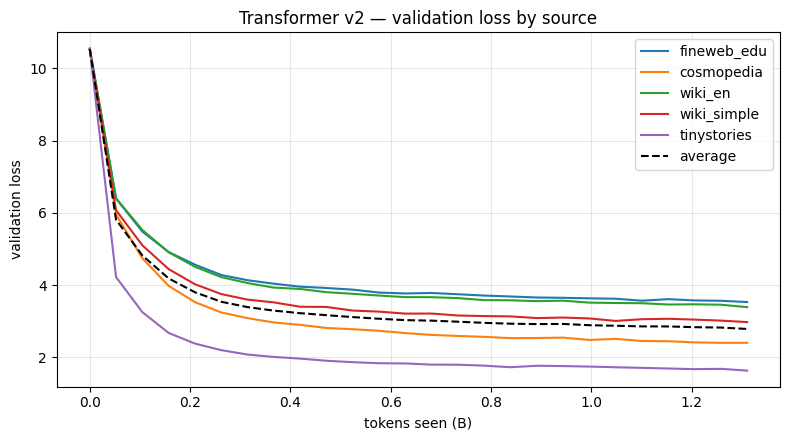

latest (step 2500): fineweb_edu 3.532, cosmopedia 2.404, wiki_en 3.391, wiki_simple 2.977, tinystories 1.635, avg 2.788


In [8]:
import csv
import matplotlib.pyplot as plt
rows = list(csv.DictReader(open(os.path.join(OUT_DIR, "log.csv"))))
tok_b = [int(r["tokens"]) / 1e9 for r in rows]
plt.figure(figsize=(8, 4.5))
for col in [c for c in rows[0] if c.startswith("val_") and c != "val_avg"]:
    plt.plot(tok_b, [float(r[col]) for r in rows], label=col[4:])
plt.plot(tok_b, [float(r["val_avg"]) for r in rows], "k--", label="average")
plt.xlabel("tokens seen (B)"); plt.ylabel("validation loss"); plt.title("Transformer v2 — validation loss by source")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "loss_by_source.png"), dpi=120); plt.show()
last = rows[-1]
print(f"latest (step {last['step']}): " + ", ".join(f"{k[4:]} {float(v):.3f}" for k, v in last.items() if k.startswith("val_")))

## 8. What the base model writes
A base model *continues* text — it hasn't learned to answer questions yet. Good signs: fluent sentences, a plausible fact or two, the right "voice" for each prompt (encyclopedic vs story).

In [9]:
from tokenizers import Tokenizer
tok = Tokenizer.from_file(os.path.join(DATA_DIR, "tokenizer.json"))
EOT = manifest["special_tokens"]["<|endoftext|>"]
ck_file = next((p for p in [os.path.join(OUT_DIR, "final.pt"), os.path.join(OUT_DIR, "ckpt_latest.pt")] if os.path.exists(p)), None)
assert ck_file, "no checkpoint yet"
ck = torch.load(ck_file, map_location="cpu", weights_only=False)
base = GPT(ModelConfig(**RUN["model"])); base.load_state_dict(ck["model"]); base = base.to(dev).eval()
print(f"loaded {os.path.basename(ck_file)} (step {ck.get('step')}, {ck.get('tokens', 0)/1e9:.2f}B tokens)\n")
prompts = ["The capital of France is", "Photosynthesis is the process by which", "Albert Einstein was",
           "Once upon a time, a little dog", "The three states of matter are"]
for p in prompts:
    ids = torch.tensor([tok.encode(p).ids], device=dev)
    with torch.autocast("cuda", dtype=torch.float16) if dev == "cuda" else torch.no_grad():
        out = base.generate(ids, 60, temperature=0.7, top_k=40, stop_ids=(EOT,))
    print(f"▶ {tok.decode(out[0].tolist())}\n")

loaded ckpt_latest.pt (step 2536, 1.33B tokens)

▶ The capital of France is the town of Borden.

The area around Borden is mostly mountainous. Since the 19th century, it was known as the "Old City". It is one of the most important cities in France because of all the other cities in France. This city is also famous for having

▶ Photosynthesis is the process by which organic materials decompose, releasing nutrients into the soil through photosynthesis. In this process, plants release the organic compounds in the soil, releasing them into the soil. Organic matter, known as biotin, is the first organic substance to be found in the soil, and, therefore, can be found

▶ Albert Einstein was not a mathematician, for his great interest in the study of the universe wasn’t a scientific idea, but a physicist himself. Einstein’s work in the sciences, which he wrote in the late 1950s, was one of the most exciting and brilliant ideas of humankind to explore. Einstein had

▶ Once upon a time, a littl

## 9. Save the base model for Step 3
Writes `pretrained.pt` (fp16 weights + config, ~200 MB). Step 3 (fine-tuning) attaches this notebook's output and loads it. Checkpoints stay in the output too, in case you want to continue training later.

In [10]:
if os.path.exists(os.path.join(OUT_DIR, "final.pt")):
    fin = torch.load(os.path.join(OUT_DIR, "final.pt"), map_location="cpu", weights_only=False)
    torch.save({"model": {k: v.half() for k, v in fin["model"].items()}, "config": fin["config"],
                "tokens": fin["tokens"], "arch": "transformer_v2"}, os.path.join(OUT_DIR, "pretrained.pt"))
    shutil.copy("model_v2.py", OUT_DIR); shutil.copy("run_config.json", OUT_DIR)
    print("saved pretrained.pt —", round(os.path.getsize(os.path.join(OUT_DIR, "pretrained.pt")) / 1e6), "MB")
else:
    print("Training not finished yet — Save Version now, then start a new session with this output attached.")
print(sorted(os.listdir(OUT_DIR)))

Training not finished yet — Save Version now, then start a new session with this output attached.
['ckpt_latest.pt', 'ckpt_meta.json', 'ckpt_prev.pt', 'log.csv', 'loss_by_source.png', 'speed_test.json']
